# Lab 07: The Periodic Quasar

**ASTR 457, Fall 2026, posted Thu Oct 22, due Wed Oct 28 by Noon (fork → PR, as always)**

Today we looked at time series and Gaussian processes. "I found a period" is one of the most-retracted sentences in astronomy, because a periodic claim is only as good as your model of the noise, and quasar noise is not white.

A survey team monitoring quasars in the g band reports a tentative periodic modulation in one of them. A quasar whose brightness repeats could be two supermassive black holes in orbit. Each of you has a quasar: `data/<your netid>.csv`, with columns `t_days` (days since the first epoch), `mag_g` and `sigma_mag` (the pipeline's per-epoch uncertainty, which you can trust). Three observing seasons over about 970 days, 240 to 290 epochs.

Quasars vary all the time with no period at all. Their light curves are well described by a **damped random walk** (DRW): the next value is a decayed copy of the last one plus a random kick. It is a Gaussian process with the exponential covariance function

$$k(\Delta t) = \sigma^2\,\exp\!\left(-\frac{|\Delta t|}{\tau}\right),$$

where $\sigma$ is the rms variability in magnitudes and $\tau$ is the damping time in days, how long the light curve remembers where it was.

I generated your light curve, so I know $\sigma$ and $\tau$, and whether there is a periodic signal in it. For some of you there isn't, and "no evidence" is then the right answer. Your $\sigma$ and $\tau$ are graded against the truth in units of your own error bar, so don't sandbag the error bar either: a 68% interval on $\ln\tau$ wider than $3\times$ the reference width I compute for your dataset (same prior as Part 2, or the profile likelihood) is capped. For the periodicity question I grade the evidence you present, not only the verdict.

Use whatever tools you like, including AI assistants, and document it in Part 6. You may be selected to defend this lab orally.

Weights: Part 1 10%, Part 2 30%, Part 3 20%, Part 4 25%, Part 5 5%, Part 6 10%.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from astropy.timeseries import LombScargle

NETID = 'ym31'   # <-- set this
d = np.genfromtxt(f'../../labs/07/data/{NETID}.csv', delimiter=',', names=True)
t, y, e = d['t_days'], d['mag_g'], d['sigma_mag']
T = t.max() - t.min()
print(f"{t.size} epochs over {T:.0f} days; median quoted error {np.median(e):.3f} mag; rms of the light curve {y.std():.3f} mag")

243 epochs over 953 days; median quoted error 0.040 mag; rms of the light curve 0.173 mag


## Part 1: Look first, then the periodogram and its window (10%)

Plot the light curve with its error bars, and look at it. Then compute a Lomb-Scargle periodogram (`astropy.timeseries.LombScargle`, using the errors) over periods from 20 days to $T/2$, where $T$ is the length of your light curve, on a frequency grid no coarser than $1/(5T)$. Compute the **window function**, the periodogram of the sampling alone: `LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False)`, scaled to the same maximum as your periodogram (only the peak positions mean anything). Plot both. Report the highest peak and astropy's `false_alarm_probability` for it.

Answer in a few sentences: what period is the highest peak, which other peaks are probably aliases of it or of the sampling, why not search beyond $T/2$, and what noise model does astropy's false-alarm probability assume?


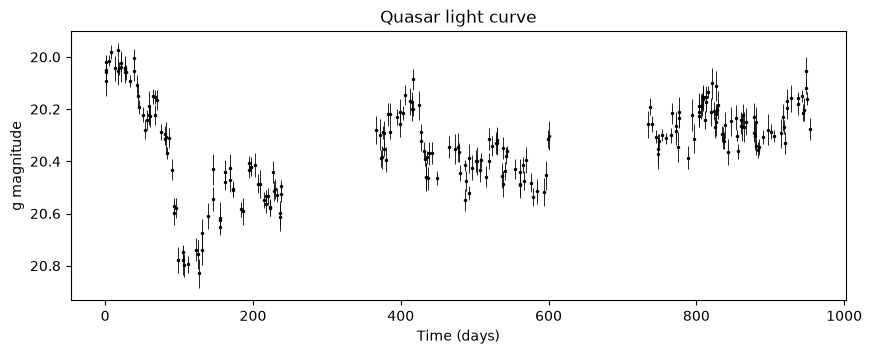

season gaps (days): [128. 134.]


In [2]:
# light curve
plt.figure(figsize=(10, 3.5))
plt.errorbar(t, y, yerr=e, fmt='.', color='k', ms=3, elinewidth=0.6)
plt.gca().invert_yaxis()
plt.xlabel('Time (days)')
plt.ylabel('g magnitude')
plt.title('Quasar light curve')
plt.show()

gaps = np.diff(t)
print('season gaps (days):', gaps[gaps > 60].round(0))

In [3]:
# Lomb-Scargle from 20 d to T/2, frequency step 1/(10T)
fmin = 1 / (T / 2)
fmax = 1 / 20
# freq = np.linspace(fmin, fmax, 5000)
freq = np.arange(fmin, fmax, 1 / (10 * T))

ls = LombScargle(t, y, e)
power = ls.power(freq)

# window function
win = LombScargle(t, np.ones_like(y), fit_mean=False, center_data=False).power(freq)
win = win / win.max() * power.max()

i_best = np.argmax(power)
P_peak = 1 / freq[i_best]
pow_peak = power[i_best]
fap = ls.false_alarm_probability(pow_peak, minimum_frequency=fmin, maximum_frequency=fmax)
print('highest peak at P =', round(P_peak, 1), 'd, power =', round(pow_peak, 3))
print('astropy FAP =', fap)

# local maxima, to see the other peaks
def local_max(p):
    idx = []
    for i in range(1, len(p) - 1):
        if p[i] > p[i - 1] and p[i] > p[i + 1]:
            idx.append(i)
    idx = np.array(idx)
    return idx[np.argsort(p[idx])[::-1]]

print('data peaks (d):', np.round(1 / freq[local_max(power)[:5]]))
print('window peaks (d):', np.round(1 / freq[local_max(win)[:3]]))

highest peak at P = 433.4 d, power = 0.441
astropy FAP = 2.976943183654739e-28
data peaks (d): [433. 340. 131. 191. 154.]
window peaks (d): [381. 180.  29.]


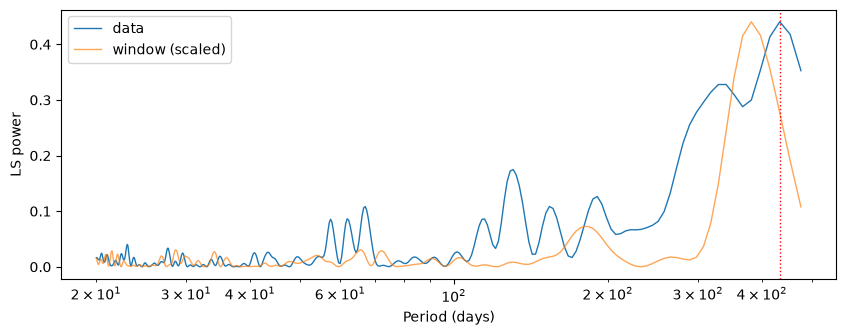

In [4]:
plt.figure(figsize=(10, 3.5))
plt.plot(1 / freq, power, lw=1, label='data')
plt.plot(1 / freq, win, lw=1, alpha=0.7, label='window (scaled)')
plt.axvline(P_peak, color='r', ls=':', lw=1)
plt.xscale('log')
plt.xlabel('Period (days)')
plt.ylabel('LS power')
plt.legend()
plt.show()

**ANSWER (a few sentences):**

Looking at the light curve it goes up and down by a few tenths of a magnitude over months, there are three seasons with two gaps of about 130 days in between and I dont see any obvious repeating pattern. The highest peak in the periodgram is at P ~ 433 d (power 0.44) and the astropy false alarm probability is 3e-28.

The biggest peak of the window function is at about 381 d which should be the yearly observing seasons, and there are smaller ones at ~180 d (half a year) and ~29 d (probably the moon). The 433 d peak is right next to the 381 d window peak, so I think a lot of the power there comes from the slow changes of the quasar combined with the yearly gaps. The ~191 d peak is close to where the yearly alias of 433 d should be (1/(1/433 + 1/365) ~ 198 d) and also close to the 180 d window peak, so it is probably an alias. The 340 d peak looks like part of the same wide bump as 433 d. The 131 and 154 d peaks don't match anything in the window so I think they are just from the red noise.

We don't look past T/2 because then there would be less than two full cycles in the data, and a slow trend can always be fit by one sinusoid. The astropy FAP assumes white noise, so every point is independent with Gaussian errors equal to the quoted errors. For a quasar that is not true since nights close together are correlated, so the FAP is way too small.

## Part 2: The Gaussian process (30%)

Model the light curve as a constant mean $\mu$ plus a DRW plus the measurement noise. The data $\mathbf{y}$ are one draw from a multivariate Gaussian,

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi, \qquad C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\,\delta_{ij},$$

where $\sigma_i$ is the quoted error of epoch $i$ and $\sigma$ without a subscript is the DRW amplitude. $N$ is about 250, so one likelihood evaluation is milliseconds with a Cholesky factorization.

1. Write the log-likelihood, log-prior and log-posterior for $(\mu, \ln\sigma, \ln\tau)$. Use priors uniform in $\ln\sigma$ and $\ln\tau$, bounded to $0.01 < \sigma < 3$ mag and $10 < \tau < 4000$ d, justify each in a line, and say what the bound on $\tau$ does to your result.
2. Find the maximum-likelihood point from more than one starting value, and say why. Then get uncertainties on $\sigma$ and $\tau$ with `emcee` (you know how from Lab 05; say how you checked convergence) or with a profile likelihood over $\tau$ (maximize over $\mu$ and $\sigma$ at each $\tau$ on a grid from 10 to 4000 d; the interval is where $\Delta(-2\ln L) = 1$). Report $\sigma$ and $\tau$ as medians with 68% intervals (or best fit with a profile interval), and $T/\tau$. The $\tau$ interval won't be symmetric; report it as it is, and say what makes $\tau$ hard to measure from a light curve this long.
3. Refit with a squared-exponential kernel, $k = \sigma^2 e^{-\Delta t^2/2\ell^2}$ (same number of parameters). Which has the higher maximum $\ln L$, by how much, and what does that say about how smooth a quasar light curve is?
4. Plot the posterior-mean prediction and its 68% band for your best kernel on a regular time grid spanning one seasonal gap, with the data. Say whether your band is for the latent light curve or for a new measurement, and why that matters against data points.
5. Hold out four non-overlapping blocks of 30 consecutive days, each inside one observing season and at least 60 days apart (random, fixed seed, redraw until they satisfy that). Fit on the rest, predict the held-out points, and compare them with the band that includes the measurement noise. Report the number held out, the fraction inside the 68% band, and the $R^2$ of the predictions against the training mean. Do the same for the other kernel. Does the band look reasonable?

#### Hints:
- get $\ln|C|$ from the diagonal of the Cholesky factor (`scipy.linalg.cho_factor`, `cho_solve`), never from `np.linalg.det`
- a few thousand `emcee` steps is enough and takes a few minutes; ten thousand is not needed
- with about 40 held-out points the fraction inside the band scatters by roughly $\pm 7\%$, so judge it accordingly

**FINAL ANSWER:** $\sigma = $ ___ (+___ / −___) mag, $\tau = $ ___ (+___ / −___) d, $T/\tau = $ ___; the exponential kernel beats the squared exponential by $\Delta\ln L = $ ___; ___ of ___ held-out points are inside the 68% band.


In [5]:
lags = np.abs(t[:, None] - t[None, :])
print(lags.shape)

def kernel(lag, amp, scale, which='drw'):
    if which == 'drw':
        return amp**2 * np.exp(-lag / scale)
    else:   # squared exponential
        return amp**2 * np.exp(-0.5 * (lag / scale)**2)

def log_like(theta, which='drw'):
    mu, lnsig, lntau = theta
    C = kernel(lags, np.exp(lnsig), np.exp(lntau), which) + np.diag(e**2)
    try:
        cfac = cho_factor(C)
    except np.linalg.LinAlgError:
        return -np.inf
    r = y - mu
    logdet = 2 * np.sum(np.log(np.diag(cfac[0])))
    return -0.5 * r @ cho_solve(cfac, r) - 0.5 * logdet - 0.5 * len(y) * np.log(2 * np.pi)

def log_prior(theta):
    mu, lnsig, lntau = theta
    sig = np.exp(lnsig)
    tau = np.exp(lntau)
    if sig <= 0.01 or sig >= 3:
        return -np.inf
    if tau <= 10 or tau >= 4000:
        return -np.inf
    return 0.0

def log_post(theta):
    lp = log_prior(theta)
    if lp == -np.inf:
        return -np.inf
    return lp + log_like(theta)

(243, 243)


The model is $C_{ij} = \sigma^2 e^{-|t_i-t_j|/\tau} + \sigma_i^2\delta_{ij}$ with

$$\ln L = -\tfrac12 (\mathbf{y}-\mu)^T C^{-1} (\mathbf{y}-\mu) - \tfrac12 \ln|C| - \tfrac{N}{2}\ln 2\pi,$$

$\ln p(\theta) = 0$ for $0.01 < \sigma < 3$ and $10 < \tau < 4000$ (and $-\infty$ otherwise), with $\theta = (\mu, \ln\sigma, \ln\tau)$, and $\ln p(\theta|\mathbf{y}) = \ln L + \ln p(\theta) + \text{const}$.

Priors: $\mu$ is flat since the data constrain it very well. $\ln\sigma$ is uniform because $\sigma$ is a scale parameter and I don't want to favor an order of magnitude; 0.01 mag is below the photometric errors and 3 mag is far more than a quasar varies. $\ln\tau$ is uniform for the same reason; 10 d is a few times the ~2 d cadence and 4000 d is about 4 times the baseline. The upper bound on $\tau$ matters here. The likelihood drops only slowly at large $\tau$, so the posterior has a long tail and about 10% of the samples are above 2000 d. A higher bound would push the median and the upper error up, so the top of my interval is partly set by the prior.

In [6]:
# max likelihood from a few different starting points
def neg_ll(theta, which):
    return -log_like(theta, which)

def fit_ml(which):
    fits = []
    for s0 in [0.05, 0.3]:
        for tau0 in [15, 100, 1000]:
            res = minimize(neg_ll, [y.mean(), np.log(s0), np.log(tau0)], args=(which,), method='Nelder-Mead',
                           options={'xatol': 1e-6, 'fatol': 1e-8, 'maxiter': 4000})
            print(which, 'start', s0, tau0, '->', np.round(np.exp(res.x[1:]), 3), round(-res.fun, 2))
            fits.append(res)
    return min(fits, key=lambda r: r.fun)

ml = fit_ml('drw')
mu_ml = ml.x[0]
sig_ml = np.exp(ml.x[1])
tau_ml = np.exp(ml.x[2])
lnL_drw = -ml.fun
print('ML: mu =', round(mu_ml, 3), ' sigma =', round(sig_ml, 3), ' tau =', round(tau_ml, 1), ' lnL =', round(lnL_drw, 2))

drw start 0.05 15 -> [ 0.168 89.799] 332.24


drw start 0.05 100 -> [ 0.168 89.799] 332.24


drw start 0.05 1000 -> [ 0.168 89.799] 332.24


drw start 0.3 15 -> [ 0.168 89.799] 332.24


drw start 0.3 100 -> [ 0.168 89.799] 332.24


drw start 0.3 1000 -> [ 0.168 89.799] 332.24
ML: mu = 20.314  sigma = 0.168  tau = 89.8  lnL = 332.24


In [7]:
np.random.seed(12)
nwalkers = 24
nsteps = 4000
p0 = ml.x + 1e-3 * np.random.randn(nwalkers, 3)
sampler = emcee.EnsembleSampler(nwalkers, 3, log_post)
sampler.run_mcmc(p0, nsteps, progress=False)

print('autocorrelation times:', sampler.get_autocorr_time(tol=0))
print('nsteps / tau:', nsteps / sampler.get_autocorr_time(tol=0))
print('acceptance:', np.mean(sampler.acceptance_fraction))

autocorrelation times: [57.25836878 56.83034564 56.14968128]
nsteps / tau: [69.8587837  70.38493176 71.23816038]
acceptance: 0.5938958333333333


sigma : 0.278 + 0.362 - 0.103
tau : 258.676 + 1139.435 - 160.653
T/tau : 3.686 + 6.04 - 3.004
fraction of tau samples > 2000 d: 0.10454166666666667


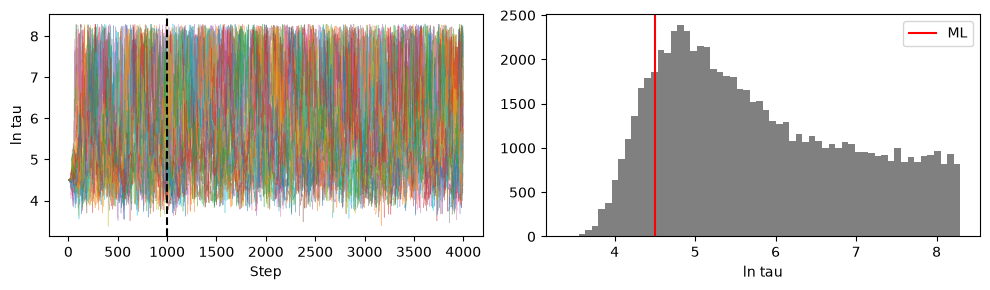

In [8]:
burn = 1000
flat = sampler.get_chain(discard=burn, flat=True)
sig_samp = np.exp(flat[:, 1])
tau_samp = np.exp(flat[:, 2])

for name, v in [('sigma', sig_samp), ('tau', tau_samp), ('T/tau', T / tau_samp)]:
    q = np.percentile(v, [16, 50, 84])
    print(name, ':', round(q[1], 3), '+', round(q[2] - q[1], 3), '-', round(q[1] - q[0], 3))
print('fraction of tau samples > 2000 d:', np.mean(tau_samp > 2000))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(sampler.get_chain()[:, :, 2], lw=0.4, alpha=0.5)
ax[0].axvline(burn, color='k', ls='--')
ax[0].set_xlabel('Step')
ax[0].set_ylabel('ln tau')
ax[1].hist(flat[:, 2], bins=60, color='gray')
ax[1].axvline(np.log(tau_ml), color='r', label='ML')
ax[1].set_xlabel('ln tau')
ax[1].legend()
plt.tight_layout()
plt.show()

I started the optimizer from 6 different $(\sigma, \tau)$ values because the likelihood could have more than one local maximum. All of them found the same point: $\sigma = 0.168$ mag, $\tau = 89.8$ d, $\ln L = 332.24$.

For emcee I used 24 walkers and 4000 steps with 1000 burn-in. The autocorrelaton times are about 57 steps, so the chain is ~75 autocorrelation times long (more than the 50 from Lab 05), the acceptance fraction is 0.59 and the trace of $\ln\tau$ looks stationary after the burn-in.

The $\tau$ interval is very asymmetric. With T/tau ~ 3.7 the light curve only covers a few damping times, so the long-timescale part of the DRW is poorly measured: a longer $\tau$ with a larger $\sigma$ looks almost the same over 950 days. This is also why the posterior median is much larger than the ML value of 90 d.

In [9]:
# squared exponential kernel
ml_se = fit_ml('sqexp')
lnL_se = -ml_se.fun
print('SE: sigma =', round(np.exp(ml_se.x[1]), 3), ' ell =', round(np.exp(ml_se.x[2]), 1), ' lnL =', round(lnL_se, 2))
print('lnL(DRW) - lnL(SE) =', round(lnL_drw - lnL_se, 1))

sqexp start 0.05 15 -> [ 0.146 11.704] 319.57


sqexp start 0.05 100 -> [ 0.146 11.704] 319.57


sqexp start 0.05 1000 -> [ 0.146 11.704] 319.57


sqexp start 0.3 15 -> [ 0.146 11.704] 319.57


sqexp start 0.3 100 -> [ 0.146 11.704] 319.57


sqexp start 0.3 1000 -> [ 0.146 11.704] 319.57
SE: sigma = 0.146  ell = 11.7  lnL = 319.57
lnL(DRW) - lnL(SE) = 12.7


The exponential kernel has $\ln L = 332.2$ and the squared exponential 319.6, so the DRW is better by $\Delta \ln L = 12.7$ with the same number of parameters. The SE fit also goes to a short $\ell = 11.7$ d to follow the night to night roughness. So the quasar light curve is rough rather than smooth, and an infinitely smooth kernel is the wrong model.

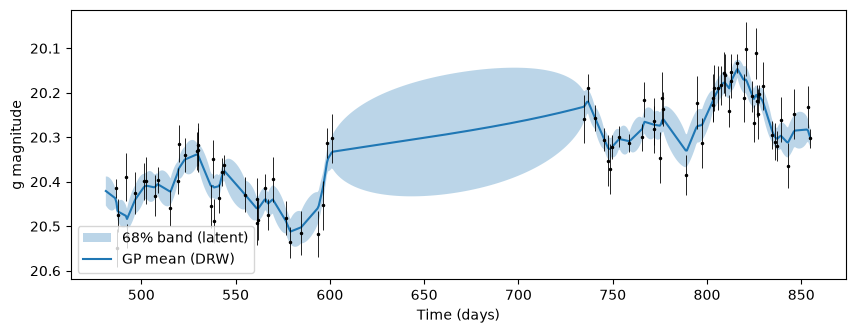

In [10]:
# GP conditional mean and std of the latent curve at new times
def gp_cond(t_tr, y_tr, e_tr, t_new, theta, which='drw'):
    mu = theta[0]
    sig = np.exp(theta[1])
    sc = np.exp(theta[2])
    K = kernel(np.abs(t_tr[:, None] - t_tr[None, :]), sig, sc, which) + np.diag(e_tr**2)
    cfac = cho_factor(K)
    Kx = kernel(np.abs(t_new[:, None] - t_tr[None, :]), sig, sc, which)
    mean = mu + Kx @ cho_solve(cfac, y_tr - mu)
    cov = kernel(0.0, sig, sc, which) - np.diag(Kx @ cho_solve(cfac, Kx.T))
    cov[cov < 0] = 0
    return mean, np.sqrt(cov)

# biggest seasonal gap
j = np.argmax(np.diff(t))
tgrid = np.linspace(t[j] - 120, t[j + 1] + 120, 600)
m_grid, s_grid = gp_cond(t, y, e, tgrid, ml.x)
show = (t > tgrid[0]) & (t < tgrid[-1])

plt.figure(figsize=(10, 3.5))
plt.fill_between(tgrid, m_grid - s_grid, m_grid + s_grid, alpha=0.3, label='68% band (latent)')
plt.plot(tgrid, m_grid, label='GP mean (DRW)')
plt.errorbar(t[show], y[show], yerr=e[show], fmt='k.', ms=3, elinewidth=0.6)
plt.gca().invert_yaxis()
plt.xlabel('Time (days)')
plt.ylabel('g magnitude')
plt.legend(loc='lower left')
plt.show()

The band in the gap plot is for the latent light curve, without measurement noise. That matters because the data scatter around the true curve by their errors (~0.04 mag), so lots of points fall outside the latent band even if the model is right. For the held-out points I use the band with $\sigma_i^2$ added.

In [11]:
# hold out 4 blocks of 30 days
# the seasonal gaps as (start, end) intervals
big = np.where(np.diff(t) > 60)[0]
gap_list = [(t[j], t[j + 1]) for j in big]

def block_ok(s0):
    # block has to be inside the data and not overlap a seasonal gap
    if s0 < t.min() or s0 + 30 > t.max():
        return False
    for g0, g1 in gap_list:
        if s0 + 30 > g0 and s0 < g1:
            return False
    return True

rng = np.random.default_rng(31)
tries = 0
while True:
    tries += 1
    starts = np.sort(rng.uniform(t.min(), t.max() - 30, 4))
    if not all(block_ok(s0) for s0 in starts):
        continue
    space = starts[1:] - starts[:-1] - 30   # days between end of one block and start of the next
    if space.min() >= 60:
        break
print('tries:', tries)

test = np.zeros(len(t), dtype=bool)
for s0 in starts:
    test[(t >= s0) & (t < s0 + 30)] = True
train = ~test
print('block starts:', starts.round(0), ' held out:', test.sum())

tries: 205
block starts: [ 69. 165. 566. 786.]  held out: 38


DRW: 23 of 38 inside 68% band, R2 = 0.67
SE:  24 of 38 inside 68% band, R2 = 0.48


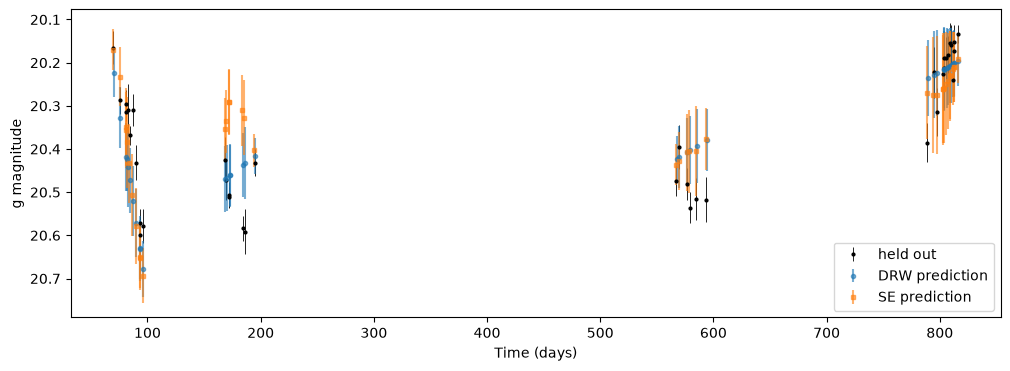

In [12]:
def holdout(which):
    best = None
    for sc0 in [15, 100, 1000]:
        res = minimize(lambda th: -train_ll(th, which), [y[train].mean(), np.log(0.15), np.log(sc0)],
                       method='Nelder-Mead', options={'maxiter': 4000})
        if best is None or res.fun < best.fun:
            best = res
    m, s = gp_cond(t[train], y[train], e[train], t[test], best.x, which)
    s_new = np.sqrt(s**2 + e[test]**2)    # band for a new measurement
    n_in = np.sum(np.abs(y[test] - m) < s_new)
    R2 = 1 - np.sum((y[test] - m)**2) / np.sum((y[test] - y[train].mean())**2)
    return n_in, R2, m, s_new

def train_ll(theta, which):
    sig = np.exp(theta[1])
    sc = np.exp(theta[2])
    K = kernel(np.abs(t[train][:, None] - t[train][None, :]), sig, sc, which) + np.diag(e[train]**2)
    cfac = cho_factor(K)
    r = y[train] - theta[0]
    return -0.5 * r @ cho_solve(cfac, r) - np.sum(np.log(np.diag(cfac[0])))

n_drw, R2_drw, m_drw, s_drw = holdout('drw')
n_se, R2_se, m_se, s_se = holdout('sqexp')
print('DRW:', n_drw, 'of', test.sum(), 'inside 68% band, R2 =', round(R2_drw, 2))
print('SE: ', n_se, 'of', test.sum(), 'inside 68% band, R2 =', round(R2_se, 2))

plt.figure(figsize=(12, 4))
plt.errorbar(t[test], y[test], yerr=e[test], fmt='k.', ms=4, elinewidth=0.6, label='held out')
plt.errorbar(t[test] + 0.3, m_drw, yerr=s_drw, fmt='o', ms=3, alpha=0.6, label='DRW prediction')
plt.errorbar(t[test] - 0.3, m_se, yerr=s_se, fmt='s', ms=3, alpha=0.6, label='SE prediction')
plt.gca().invert_yaxis()
plt.xlabel('Time (days)')
plt.ylabel('g magnitude')
plt.legend()
plt.show()

38 points were held out in the four blocks. For the DRW 23 of 38 (61%) are inside the 68% band with R^2 = 0.67, and for the SE 24 of 38 (63%) with R^2 = 0.48. With ~40 points the fraction scatters by about 7%, so 61% is a little low but within the scatter, and the band looks reasonable. The coverage is about the same for both kernels, but the DRW predicts the held-out points a lot better, which agrees with the likelihood.

**FINAL ANSWER:** $\sigma = 0.28$ (+0.36 / -0.10) mag, $\tau = 259$ (+1139 / -161) d, $T/\tau = 3.7$ (+6.0 / -3.0); the exponential kernel beats the squared exponential by $\Delta\ln L = 12.7$; 23 of 38 held-out points are inside the 68% band.

## Part 3: Is it periodic? (20%)

The question is whether the highest peak is too tall to be noise, so the answer depends on the noise model.

1. Before you run anything in this part, write in a markdown cell above your code the empirical $p$-value below which you would claim a period, and why. No changing it afterwards.
2. Simulate at least 1000 DRW light curves with your Part 2 maximum-likelihood $\mu$, $\sigma$ and $\tau$, at your epochs and with your errors: $\mathbf{y} = \mu + L\mathbf{z} + $ noise, with $L$ the Cholesky factor of the DRW covariance, $\mathbf{z}$ standard normal, and a Gaussian draw with each $\sigma_i$. Run the same Lomb-Scargle search (20 d to $T/2$) on every one, record the highest peak in each, and report the fraction whose highest peak is at least as tall as yours. That is your empirical $p$-value. Compare it with astropy's false-alarm probability from Part 1 and explain the difference.
3. Fit $y = \mu + A\sin(2\pi t/P + \phi) + \mathrm{DRW}$. For fixed $\sigma$, $\tau$ (the Part 2 maximum-likelihood values; say how your $p$-value changes at the two ends of your $\tau$ interval) and a fixed period, the amplitudes enter linearly, so $\hat\theta = (X^T C^{-1} X)^{-1} X^T C^{-1}\mathbf{y}$ with columns $1, \cos 2\pi t/P, \sin 2\pi t/P$. Scan the period from 20 d to $T/2$, record the best $\Delta\chi^2$ against the constant-mean model, and compare it with the same statistic on your simulated light curves (the simulations are what account for the look-elsewhere effect).
4. Is there evidence for a periodic signal, by your own rule? If yes, give a period and an amplitude with uncertainties; if no, say what you would need to see. One sentence: should the team announce a binary candidate on this evidence?

#### Hints:
- 300 simulations cannot resolve a $p$-value of 0.01


Decision rule (written before running Part 3): I will claim a period only if the empirical p-value from the DRW simulations is below 0.01 for both the Lomb-Scargle peak and the best $\Delta\chi^2$ of the sinusoid scan. I use 0.01 instead of 0.05 because claiming a binary black hole is a big claim, so I want to be more strict, and 1000 simulations is enough to resolve 0.01.

(243, 1000)


empirical p = 0.223   astropy FAP = 2.976943183654739e-28
50/90/99 percentiles of the sim peaks: [0.35  0.515 0.652]


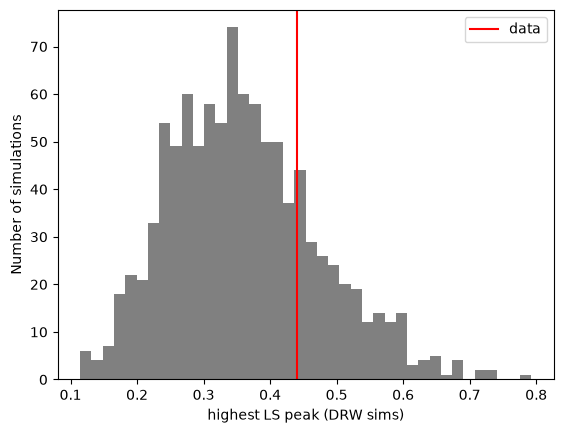

In [13]:
# DRW simulations at the ML parameters, same times and errors
def sim_drw(mu, sig, tau, nsim, seed):
    gen = np.random.default_rng(seed)
    L = np.linalg.cholesky(kernel(lags, sig, tau))
    z = gen.normal(size=(len(t), nsim))
    noise = e[:, None] * gen.normal(size=(len(t), nsim))
    return mu + L @ z + noise

nsim = 1000
ysim = sim_drw(mu_ml, sig_ml, tau_ml, nsim, seed=7)
print(ysim.shape)

peak_sim = np.zeros(nsim)
for i in range(nsim):
    peak_sim[i] = LombScargle(t, ysim[:, i], e).power(freq).max()

p_ls = np.mean(peak_sim >= pow_peak)
print('empirical p =', p_ls, '  astropy FAP =', fap)
print('50/90/99 percentiles of the sim peaks:', np.percentile(peak_sim, [50, 90, 99]).round(3))

plt.figure()
plt.hist(peak_sim, bins=40, color='gray')
plt.axvline(pow_peak, color='r', label='data')
plt.xlabel('highest LS peak (DRW sims)')
plt.ylabel('Number of simulations')
plt.legend()
plt.show()

data: best delta chi2 = 12.7 at P = 66 d
empirical p = 0.164


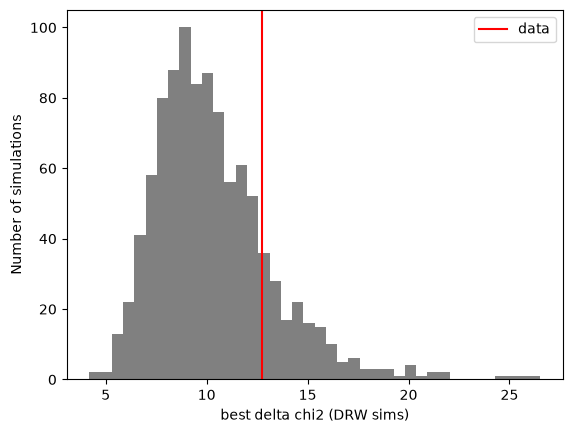

In [14]:
# sinusoid + DRW with sigma, tau fixed: theta_hat = (X^T C^-1 X)^-1 X^T C^-1 y at each period
def dchi2_scan(Y, sig, tau, tt=t, ee=e, fgrid=freq):
    C = kernel(np.abs(tt[:, None] - tt[None, :]), sig, tau) + np.diag(ee**2)
    cfac = cho_factor(C)
    CinvY = cho_solve(cfac, Y)
    one = np.ones(len(tt))
    Cinv1 = cho_solve(cfac, one)
    chi2_const = np.sum(Y * CinvY, axis=0) - (Cinv1 @ Y)**2 / (one @ Cinv1)
    best = np.zeros(Y.shape[1])
    best_P = np.zeros(Y.shape[1])
    for f in fgrid:
        X = np.column_stack([one, np.cos(2 * np.pi * f * tt), np.sin(2 * np.pi * f * tt)])
        CinvX = cho_solve(cfac, X)
        A = X.T @ CinvX
        b = CinvX.T @ Y
        chi2_sin = np.sum(Y * CinvY, axis=0) - np.sum(b * np.linalg.solve(A, b), axis=0)
        d = chi2_const - chi2_sin
        better = d > best
        best[better] = d[better]
        best_P[better] = 1 / f
    return best, best_P

d_data, P_data = dchi2_scan(y[:, None], sig_ml, tau_ml)
d_sims, _ = dchi2_scan(ysim, sig_ml, tau_ml)
p_gls = np.mean(d_sims >= d_data[0])
print('data: best delta chi2 =', round(d_data[0], 1), 'at P =', round(P_data[0]), 'd')
print('empirical p =', p_gls)

plt.figure()
plt.hist(d_sims, bins=40, color='gray')
plt.axvline(d_data[0], color='r', label='data')
plt.xlabel('best delta chi2 (DRW sims)')
plt.ylabel('Number of simulations')
plt.legend()
plt.show()

In [15]:
# p-value at the two ends of the tau interval
# refit sigma at each tau
from scipy.optimize import minimize_scalar
tau_lo, tau_hi = np.percentile(tau_samp, [16, 84])
for tau_end in [tau_lo, tau_hi]:
    best_s = minimize_scalar(lambda ls: -log_like([mu_ml, ls, np.log(tau_end)]), bounds=(np.log(0.01), np.log(3)), method='bounded')
    sig_end = np.exp(best_s.x)
    ys_end = sim_drw(mu_ml, sig_end, tau_end, nsim, seed=8)
    d_o, _ = dchi2_scan(y[:, None], sig_end, tau_end)
    d_s, _ = dchi2_scan(ys_end, sig_end, tau_end)
    print('tau =', round(tau_end), 'd, sigma =', round(sig_end, 3), ': data delta chi2 =', round(d_o[0], 1), ' p =', np.mean(d_s >= d_o[0]))

tau = 98 d, sigma = 0.174 : data delta chi2 = 12.8  p = 0.189


tau = 1398 d, sigma = 0.634 : data delta chi2 = 13.0  p = 0.17


**ANSWER (the decision rule first, then the verdict):**

Rule: claim a period only if both empirical p-values are below 0.01.

The 433 d peak is matched or beaten by 22% of the 1000 DRW simualtions, so p = 0.22. Astropy gave 3e-28 because it compares against white noise, but with DRW noise a peak like this at a long period happens pretty often.

The sinusoid + DRW scan has its best $\Delta\chi^2 = 12.7$ at P = 66 d, and the simulations give p = 0.16. At the ends of the $\tau$ interval, refitting $\sigma$ each time, $p$ is 0.19 ($\tau = 98$ d) and 0.17 ($\tau = 1398$ d), so it does not depend much on $\tau$.

So by my rule there is no evidence for a periodic signal, both p-values are around 0.2 which is nowhere near 0.01. To claim a period I would need p < 0.01 against the DRW and also to see the same period repeat for a lot of cycles, so the light curve would need to be several times longer than P (for 433 d that's more than 5 years). The team should not announce a binary candidate on this evidence, the peak is not unusual for DRW noise.

## Part 4: The referee report (25%)

`ai_solution.ipynb` in this directory is a complete analysis of this exact problem by an AI assistant. It runs top to bottom without errors. It is also wrong in at least **three** distinct, substantive ways (style and cosmetics don't count; "it used 5-fold cross-validation and I used four blocks" is not a finding by itself).

Write a referee report:

1. Identify at least three substantive statistical errors.
2. Demonstrate each one on your dataset: show, with a number or a plot, what the error does to the inference. A demonstration can come out negative: if an error does not move your numbers, show that and say what it would take for it to bite.
3. State the correct treatment (you built most of it in Parts 2 and 3).

You know the drill by now.


In [16]:
# (1) white noise FAP, using the AI notebook's own grid
freq_ai = np.linspace(1. / (T / 2.), 1. / 20., 6000)
ls_ai = LombScargle(t, y, e)
pow_ai = ls_ai.power(freq_ai)
k_ai = np.argmax(pow_ai)
fap_ai = ls_ai.false_alarm_probability(pow_ai[k_ai], minimum_frequency=freq_ai[0], maximum_frequency=freq_ai[-1])
print('AI: P =', round(1 / freq_ai[k_ai]), 'd, FAP =', fap_ai)
print('same peak against the DRW sims (Part 3): p =', p_ls)

AI: P = 435 d, FAP = 2.944389656748866e-28
same peak against the DRW sims (Part 3): p = 0.223


In [17]:
# (2) SE kernel, and the AI's curvature error on ell
h = 0.05
def f_se(dl):
    return -log_like([ml_se.x[0], ml_se.x[1], ml_se.x[2] + dl], 'sqexp')
curv = (f_se(h) - 2 * f_se(0.0) + f_se(-h)) / h**2
ell = np.exp(ml_se.x[2])
print('SE ell =', round(ell, 1), '+/-', round(ell / np.sqrt(curv), 1), 'd   vs DRW tau(ML) =', round(tau_ml), 'd')
print('lnL SE =', round(lnL_se, 1), '  lnL DRW =', round(lnL_drw, 1))

SE ell = 11.7 +/- 1.0 d   vs DRW tau(ML) = 90 d
lnL SE = 319.6   lnL DRW = 332.2


In [18]:
# (3) random 5-fold CV like the AI notebook, vs the 30 d blocks from Part 2
folds = np.random.default_rng(1).permutation(len(t)) % 5
for which, theta in [('sqexp', ml_se.x), ('drw', ml.x)]:
    m_cv = np.zeros(len(t))
    s_cv = np.zeros(len(t))
    for k in range(5):
        te = folds == k
        m_cv[te], s_cv[te] = gp_cond(t[~te], y[~te], e[~te], t[te], theta, which)
    s_cv = np.sqrt(s_cv**2 + e**2)
    R2_cv = 1 - np.sum((y - m_cv)**2) / np.sum((y - y.mean())**2)
    cover = np.mean(np.abs(y - m_cv) < s_cv)
    print(which, ': random 5-fold R2 =', round(R2_cv, 2), ' coverage =', round(cover, 2))

print('30 d blocks (Part 2): R2 SE =', round(R2_se, 2), ', R2 DRW =', round(R2_drw, 2))

sqexp : random 5-fold R2 = 0.91  coverage = 0.6
drw : random 5-fold R2 = 0.91  coverage = 0.68
30 d blocks (Part 2): R2 SE = 0.48 , R2 DRW = 0.67


**REFEREE REPORT:**

The notebook reports a period of 435 ± 8 d with FAP 3e-28 on top of smooth variability and recommends the quasar as a binary candidate. Running its steps on my light curve gives the same period and FAP. The conclusion does not hold, for three reasons.

1. The significance uses a white-noise false-alarm probability. `false_alarm_probability` assumes independent points, but quasar variability is red noise, so tall long-period peaks are expected. On my data the AI's FAP is 3e-28, but the same peak is matched by 22% of the DRW simulations (p = 0.22, Part 3). The correct test is to fit the DRW, simulate light curves at the same times and errors, and compare the peak (or the GLS $\Delta\chi^2$ with the DRW covariance) to the simulated distribution, as in Part 3.

2. The kernel is wrong. The the notebook calls the variability smooth and uses a squared exponential without comparing it to anything. On my data the SE has $\ln L = 319.6$ vs 332.2 for the exponential kernel ($\Delta\ln L = 12.7$, same number of parameters), and it shrinks to $\ell = 11.7$ d to follow the roughness, much shorter than the DRW $\tau$ (~90 d at the ML point). It should use the DRW kernel, and get the error on $\tau$ from MCMC or a profile likelihood, not from the curvature: the curvature gives a symmetric +/-1.0 d, while the DRW posterior in Part 2 has a long tail to large $\tau$.

3. Random 5-fold cross-validation leaks information. With random folds every held-out point still has its neighbours in the training set, which are only a couple of days away (much less than $\tau$), so the GP is just interpolating. The AI's setup gives R^2 = 0.91 for the SE (and 0.91 for the DRW too), while the 30 day blocks in Part 2 give 0.48 and 0.67. So the "validated" accuracy is inflated by the leak, and with random folds both kernels look the same. The fix is to hold out contiguous blocks longer than the correlation time and check the coverage of the band with measurement noise, as in Part 2.

## Part 5: A live light curve (5%)

Everything so far was a light curve I simulated. This one is real and recent. Look up your quasar in `data/live_objects.csv` (columns `netid`, `ztf_oid`). The function below pulls its g-band light curve from the public ALeRCE API for the Zwicky Transient Facility (ZTF); if the API is down it falls back to `data/live/<oid>.csv`, a copy I saved on Oct 21.


In [19]:
import requests, os
from astropy.time import Time

def get_ztf_g(oid):
    """g-band (mjd, mag, err) for a ZTF object from the ALeRCE API (corrected magnitudes, dubious points removed).
    Falls back to the cached copy data/live/<oid>.csv, and says so."""
    try:
        r = requests.get(f'https://api.alerce.online/ztf/v1/objects/{oid}/lightcurve', timeout=60)
        r.raise_for_status()
        rows = [(q['mjd'], q['magpsf_corr'], q['sigmapsf_corr_ext']) for q in r.json()['detections']
                if q['fid'] == 1 and q.get('corrected') and not q.get('dubious')
                and q.get('magpsf_corr') is not None and q.get('sigmapsf_corr_ext') is not None]
        a = np.array(sorted(rows))
        print(f'{oid}: {a.shape[0]} g-band detections from the live API')
    except Exception as ex:
        print(f'API failed ({ex!r}); using the cached copy')
        a = np.genfromtxt(f'../../labs/07/data/live/{oid}.csv', delimiter=',', skip_header=2)
    return a[:, 0], a[:, 1], a[:, 2]

live = np.genfromtxt('../../labs/07/data/live_objects.csv', delimiter=',', names=True, dtype=None, encoding=None)
OID = [r['ztf_oid'] for r in live if r['netid'] == NETID][0]
mjd, mag, merr = get_ztf_g(OID)
print(f"{OID}: MJD {mjd.min():.1f} to {mjd.max():.1f} ({(mjd.max() - mjd.min()) / 365.25:.1f} yr); the last detection is MJD {mjd.max():.1f}; today is MJD {Time.now().mjd:.0f}")

ZTF18aceijsp: 695 g-band detections from the live API
ZTF18aceijsp: MJD 58429.2 to 61030.1 (7.1 yr); the last detection is MJD 61030.1; today is MJD 61342


Apply your Part 3 standard to this light curve: state before you run it what result would make you call it periodic, then run it (nightly means are fine if the full sample is too slow for the simulations). Two or three sentences: is there evidence for a period, what is different about this sampling from your simulated light curve (look at the last detection date above and at the cadence), and what would you do next with a week more of time?


Criterion (written before running): the same as Part 3, it is periodic only if the empirical p-value is below 0.01 for both the highest LS peak and the best $\Delta\chi^2$ of the sinusoid + DRW scan, using DRW simulations with this light curve's own ML $\sigma$ and $\tau$ at the same nights and errors. I use nightly means so the simulations are faster.

In [20]:
import numpy as np
from astropy.timeseries import LombScargle

# nightly means
night = np.floor(mjd)
t_n, y_n, e_n = [], [], []
for n in np.unique(night):
    sel = night == n
    w = 1 / merr[sel]**2
    t_n.append(np.mean(mjd[sel]))
    y_n.append(np.sum(w * mag[sel]) / np.sum(w))
    e_n.append(1 / np.sqrt(np.sum(w)))
t_n = np.array(t_n) - mjd.min()
y_n = np.array(y_n)
e_n = np.array(e_n)
T_n = t_n.max()
print(len(t_n), 'nights over', round(T_n), 'days, median spacing', round(np.median(np.diff(t_n)), 1), 'd')
print('nights per year:', np.histogram(t_n, bins=np.arange(0, T_n + 365, 365))[0])

674 nights over 2601 days, median spacing 2.0 d
nights per year: [109 151  87  77  86  78  81   5]


In [21]:
lags_n = np.abs(t_n[:, None] - t_n[None, :])
def nll_live(theta):
    K = kernel(lags_n, np.exp(theta[1]), np.exp(theta[2])) + np.diag(e_n**2)
    cfac = cho_factor(K)
    r = y_n - theta[0]
    return 0.5 * r @ cho_solve(cfac, r) + np.sum(np.log(np.diag(cfac[0])))

fits = [minimize(nll_live, [y_n.mean(), np.log(0.1), np.log(tau0)], method='Nelder-Mead', options={'maxiter': 4000})
        for tau0 in [30, 300, 2000]]
best_live = min(fits, key=lambda r: r.fun)
mu_n = best_live.x[0]
sig_n = np.exp(best_live.x[1])
tau_n = np.exp(best_live.x[2])
print('DRW ML: sigma =', round(sig_n, 3), ' tau =', round(tau_n), 'd')

freq_n = np.arange(1 / (T_n / 2), 1 / 20, 1 / (10 * T_n))
ls_n = LombScargle(t_n, y_n, e_n)
pow_n = ls_n.power(freq_n)
k_n = np.argmax(pow_n)
print('highest peak P =', round(1 / freq_n[k_n]), 'd, power', round(pow_n[k_n], 3),
      ', astropy FAP', ls_n.false_alarm_probability(pow_n[k_n], minimum_frequency=freq_n[0], maximum_frequency=freq_n[-1]))

DRW ML: sigma = 0.139  tau = 107 d
highest peak P = 591 d, power 0.343 , astropy FAP 1.1657436424033908e-58


LS empirical p = 0.368


best delta chi2 = 24.4 at P = 54 d, empirical p = 0.001


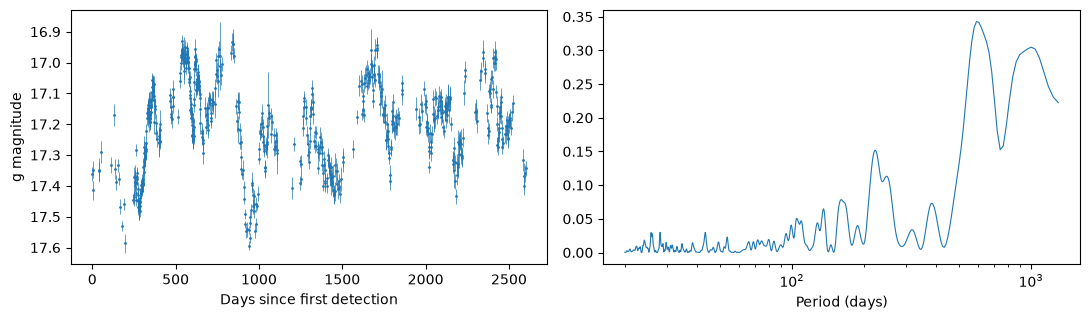

In [22]:
gen = np.random.default_rng(5)
L_n = np.linalg.cholesky(kernel(lags_n, sig_n, tau_n) + 1e-10 * np.eye(len(t_n)))
ysim_n = mu_n + L_n @ gen.normal(size=(len(t_n), 1000)) + e_n[:, None] * gen.normal(size=(len(t_n), 1000))

peaks_n = np.zeros(1000)
for i in range(1000):
    peaks_n[i] = LombScargle(t_n, ysim_n[:, i], e_n).power(freq_n).max()
print('LS empirical p =', np.mean(peaks_n >= pow_n[k_n]))

d_n, P_n = dchi2_scan(y_n[:, None], sig_n, tau_n, t_n, e_n, freq_n)
d_nsim, _ = dchi2_scan(ysim_n, sig_n, tau_n, t_n, e_n, freq_n)
print('best delta chi2 =', round(d_n[0], 1), 'at P =', round(P_n[0]), 'd, empirical p =', np.mean(d_nsim >= d_n[0]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].errorbar(t_n, y_n, yerr=e_n, fmt='.', ms=2, elinewidth=0.5)
ax[0].invert_yaxis()
ax[0].set_xlabel('Days since first detection')
ax[0].set_ylabel('g magnitude')
ax[1].plot(1 / freq_n, pow_n, lw=0.8)
ax[1].set_xscale('log')
ax[1].set_xlabel('Period (days)')
plt.tight_layout()
plt.show()

**ANSWER (the criterion first, then the result):**

Criterion: p < 0.01 for both tests. The highest LS peak (591 d, white-noise FAP 1e-58) has p = 0.37, but the sinusoid + DRW scan finds $\Delta\chi^2 = 24.4$ at P = 54 d with p = 0.001, so by my rule this is not a period, but the 54 d signal is interesting and I wouldnt just ignore it. Compared to my simulated light curve the sampling is ≈7 years long instead of ~2.6, the number of nights changes a lot from year to year and the last year has almost nothing, the last detection is MJD 61030, about 10 months before today. With another week I would get more data (the r band too) and check if the 54 d signal shows up in both halves of the light curve and in both bands.

## Part 6: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 2 and Part 3 numbers, and what failure would have looked like for each. One to consider: generate a synthetic DRW light curve with a $\sigma$ and $\tau$ you choose, at your epochs and errors, with and without a planted sinusoid; run your whole pipeline on it; see whether the 68% intervals contain what you put in and whether Part 3 finds the sinusoid and finds nothing when there is none. One realisation is a spot check, not a calibration: say how many you would need.


**AI-USE APPENDIX:**

I used Claude Code for this lab. I read the Day 17 lecture and the lab first, then had it write most of the code (including the Part 4 demos) and help draft the write-up, and I checked the numbers against the outputs. It got a few things wrong. When it moved $\tau$ to the ends of the interval in Part 3 it kept $\sigma$ at the ML value, which gave a huge $\Delta\chi^2$ and p = 0 at $\tau$ = 1398 d, because a long $\tau$ with the small ML $\sigma$ doesn't fit the light curve, so I refit $\sigma$ at each $\tau$. Its first Part 5 only ran the LS test even though my rule needs both tests, and when I added the sinusoid scan it found the 54 d signal. Also the emcee median for $tau$ (~260 d) is about 3 times the ML value (~90 d), which looked like a bug, but the trace and the histogram of $\ln\tau$ show it's just a long tail, so I kept the asymmetric interval.

**REFLECTION:**

I mostly used AI to write the code quickly. If I hadn't checked, Part 3 would have said the signal is significant at the upper end of the $\tau$ interval for the wrong reason, and Part 5 would have missed the 54 d signal completely.

**VERIFICATION PLAN:**

- ML fit from 5 starting points, all give the same lnL. Failure would be different maxima depending on the start.
- emcee: chain is ~70 autocorrelation times long and the traces are flat after burn-in. Failure would be the walkers still drifting.
- Part 3 p-value at both ends of the $\tau$ interval, 0.19 and 0.17. Failure would be p crossing 0.01 somewhere inside the interval.
- Not done yet: a fake DRW light curve at my epochs and errors, with and without a planted sinusoid, run through the whole pipeline. One fake dataset is only a spot check, I'd need ~100 to check the 68% coverage and a few hundred without a signal for the false-positive rate.